# Lab 9. EEG seizure recognition
This notebook predicts seizure activity in one short EEG segment. It reads the local course-format CSV from `data/Epileptic Seizure Recognition.csv`, a reshaped version of the Bonn EEG dataset distributed as [Epileptic Seizure Recognition on Kaggle](https://www.kaggle.com/datasets/harunshimanto/epileptic-seizure-recognition).

Use a Python kernel with NumPy, pandas, matplotlib, scikit-learn, SciPy and LightGBM. PyTorch is needed only for the optional CNN. Run all cells from the directory containing this notebook.

The saved run used NumPy 2.2.6, pandas 2.2.3, scikit-learn 1.6.1, SciPy 1.15.3, matplotlib 3.11.2 and LightGBM 4.7.0. PyTorch was unavailable for the optional CNN in the saved run.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                     # same seed everywhere, so results can be repeated
np.random.seed(SEED)

DATA_PATH = "data/Epileptic Seizure Recognition.csv"
SIGNAL_COLS = [f"X{i}" for i in range(1, 179)]     # X1 ... X178

## Part A: Understand the data
### A1. Load the data
Check the shape, missing values and number of rows per label.
**Result:** 11,500 rows × 180 columns, 0 missing values, 2,300 rows for each of the 5 labels.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={df.columns[0]: "id"})     # first column is the segment ID

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nRows per original label:")
print(df["y"].value_counts().sort_index())

Shape: (11500, 180)
Missing values: 0

Rows per original label:
y
1    2300
2    2300
3    2300
4    2300
5    2300
Name: count, dtype: int64


### A2. Find the recording ID
The ID `X21.V1.791` = chunk `X21` + recording `V1.791`. We keep the recording part.
**Result:** 500 recordings, each with exactly 23 rows and one label.

In [3]:
df["recording_id"] = df["id"].str.split(".", n=1).str[1]

per_recording = df.groupby("recording_id")
assert per_recording.ngroups == 500
assert per_recording.size().eq(23).all()
assert per_recording["y"].nunique().eq(1).all()
print("Number of recordings :", df["recording_id"].nunique())
print("Rows per recording   :", per_recording.size().unique())
print("Labels per recording :", per_recording["y"].nunique().unique())

Number of recordings : 500
Rows per recording   : [23]
Labels per recording : [1]


### A3. Make the binary target
`seizure = 1` if `y == 1`, otherwise `0` (labels 2–5 are all non-seizure).
**Result:** 20% seizure. Always saying "no seizure" already gives **80% accuracy**, so accuracy is a weak metric here.

In [4]:
df["seizure"] = (df["y"] == 1).astype(int)

print(df["seizure"].value_counts())
print("Seizure rows: %.1f%%" % (df["seizure"].mean() * 100))
print("Accuracy if we always say 'no seizure': %.1f%%" % ((1 - df["seizure"].mean()) * 100))

seizure
0    9200
1    2300
Name: count, dtype: int64
Seizure rows: 20.0%
Accuracy if we always say 'no seizure': 80.0%


### A4. Two example waveforms per original label
A row is one 178-sample chunk, approximately one second long. A recording has 23 such chunks from one selected single-channel trace. A person can contribute multiple recordings, and the CSV has no person ID.

Labels 2-5 all represent non-seizure segments in the lab, so combining them matches the binary review task. An always-negative classifier is 80% accurate and has 0% seizure sensitivity. The source has equal counts for the five curated labels, which fixes seizure prevalence at 20%. Continuous EEG contains a different mix of background, artefacts and seizure activity.

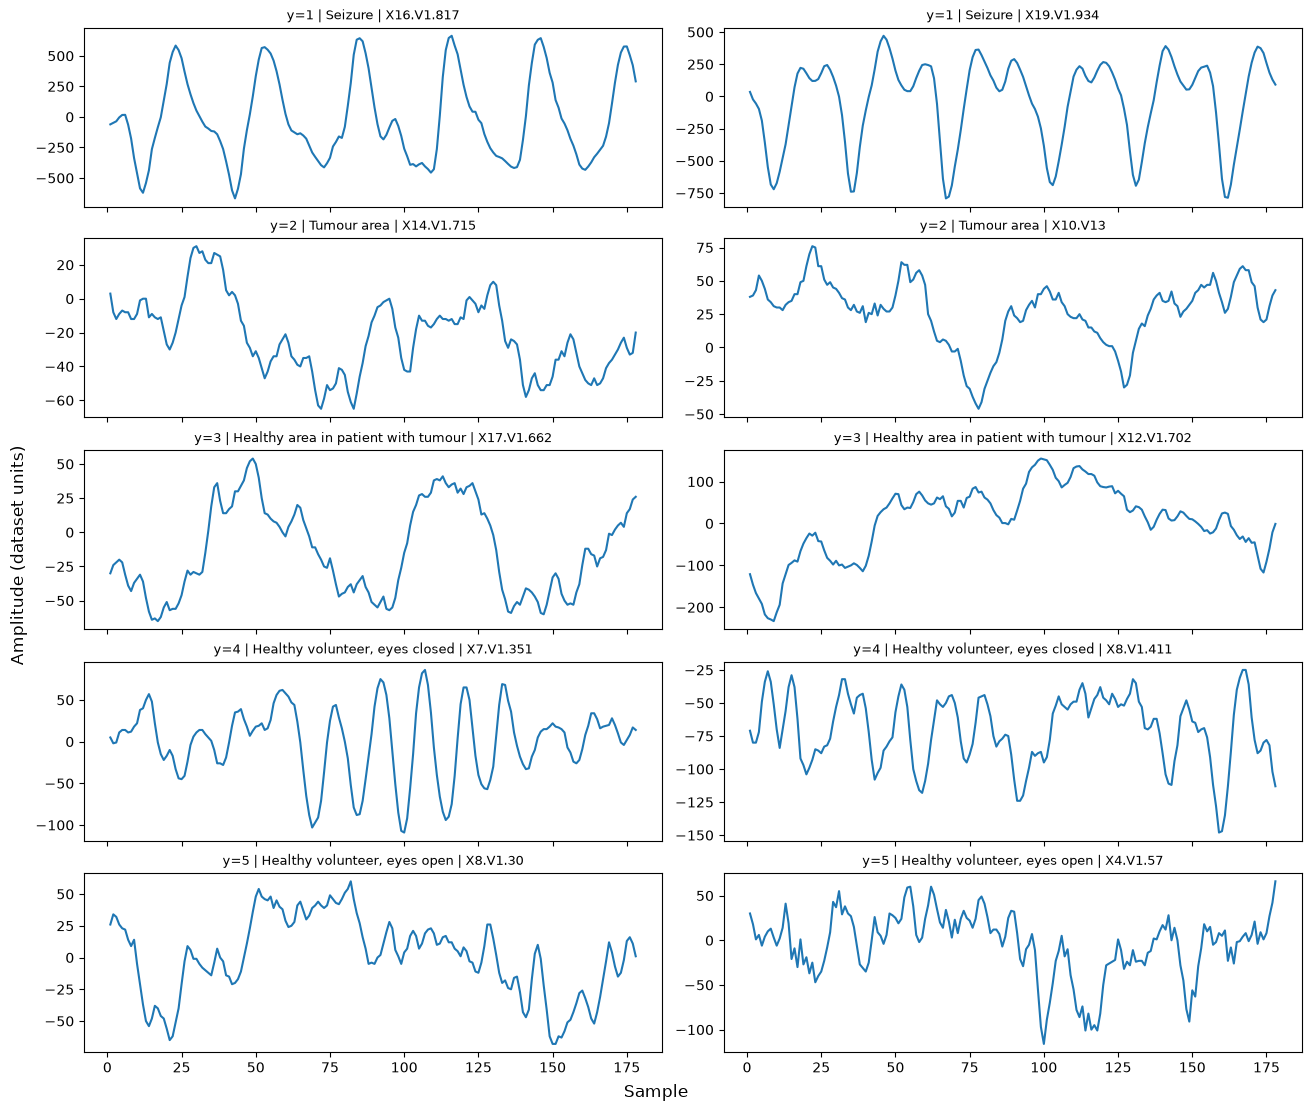

In [5]:
LABEL_NAMES = {
    1: "Seizure",
    2: "Tumour area",
    3: "Healthy area in patient with tumour",
    4: "Healthy volunteer, eyes closed",
    5: "Healthy volunteer, eyes open",
}

fig, axes = plt.subplots(5, 2, figsize=(13, 11), sharex=True, layout="constrained")
for (label, rows), row_axes in zip(df.groupby("y"), axes):
    examples = rows.drop_duplicates("recording_id").sample(2, random_state=SEED)
    for ax, (_, row) in zip(row_axes, examples.iterrows()):
        ax.plot(range(1, 179), row[SIGNAL_COLS].to_numpy(dtype=float))
        ax.set_title(f"y={label} | {LABEL_NAMES[label]} | {row['id']}", fontsize=9)
fig.supxlabel("Sample")
fig.supylabel("Amplitude (dataset units)")
plt.show()

## Part B: Split without leakage
### B1. Split by recording (60 / 20 / 20)
We split **recordings**, not rows, so all 23 chunks of a recording stay in one set. Otherwise the model could "recognise" a recording it saw in training, and test results would look too good.

In [6]:
from sklearn.model_selection import train_test_split

recordings = df.groupby("recording_id")["y"].first()      # 500 recordings and their labels

train_ids, temp_ids = train_test_split(recordings.index, test_size=0.4,
                                       stratify=recordings, random_state=SEED)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.5,
                                     stratify=recordings[temp_ids], random_state=SEED)

train = df[df["recording_id"].isin(train_ids)]
val   = df[df["recording_id"].isin(val_ids)]
held_out = df["recording_id"].isin(test_ids)

### B2. Check the split
**Result:** no recording appears in two sets. Train = 300 recordings, validation = 100, test = 100, each 20% seizure.

In [7]:
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)
assert set(train_ids) | set(val_ids) | set(test_ids) == set(recordings.index)
print("Train ∩ Val :", len(set(train_ids) & set(val_ids)))
print("Train ∩ Test:", len(set(train_ids) & set(test_ids)))
print("Val ∩ Test  :", len(set(val_ids) & set(test_ids)))

pd.DataFrame({
    "rows":       [len(train), len(val), held_out.sum()],
    "recordings": [train["recording_id"].nunique(), val["recording_id"].nunique(), len(test_ids)],
    "seizure %":  [train["seizure"].mean() * 100, val["seizure"].mean() * 100, df.loc[held_out, "seizure"].mean() * 100],
}, index=["train", "val", "test"])

Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0


,rows,recordings,seizure %
train,6900,300,20.0
val,2300,100,20.0
test,2300,100,20.0


### B3. Training-only scaling
The scaler estimates the mean and standard deviation from training signals and applies those statistics to validation inputs. Validation predictions determine the model and threshold. Test signals are first accessed in Part E.

In [8]:
from sklearn.preprocessing import StandardScaler

X_train, y_train = train[SIGNAL_COLS].values, train["seizure"].values
X_val,   y_val   = val[SIGNAL_COLS].values,   val["seizure"].values

scaler = StandardScaler().fit(X_train)       # fit on train only
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)

## Part C: Baseline, then improve step by step
### Common training + evaluation function
Every model goes through the same function: **train → predict on validation → metrics → 4 plots** (confusion matrix, ROC, precision-recall, calibration).
Metrics: accuracy, sensitivity, specificity, PPV, NPV, ROC-AUC, PR-AUC, Brier score.

In [9]:
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve, auc, brier_score_loss
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.calibration import CalibrationDisplay

def get_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)            # yes / no
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    precision, recall, _ = precision_recall_curve(y_true, prob)
    return {
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "accuracy": (tp + tn) / len(y_true),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan,
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": auc(recall, precision),
        "Brier": brier_score_loss(y_true, prob),
    }

results = {}     # metrics of every model
val_probs = {}   # validation probabilities of every model

def train_and_evaluate(name, model, X_tr, X_v):
    model.fit(X_tr, y_train)                          # 1. train
    prob = model.predict_proba(X_v)[:, 1]             # 2. probability of seizure
    pred = (prob >= 0.5).astype(int)                  # 3. yes / no
    results[name] = get_metrics(y_val, prob)          # 4. metrics
    val_probs[name] = prob

    fig, ax = plt.subplots(1, 4, figsize=(18, 4))     # 5. plots
    ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=["no seizure", "seizure"],
                                            cmap="Blues", colorbar=False, ax=ax[0])
    RocCurveDisplay.from_predictions(y_val, prob, ax=ax[1])
    PrecisionRecallDisplay.from_predictions(y_val, prob, ax=ax[2])
    CalibrationDisplay.from_predictions(y_val, prob, n_bins=10, ax=ax[3])
    ax[0].set_title("Confusion matrix (threshold 0.5)")
    ax[1].set_title("ROC curve")
    ax[2].set_title("Precision-recall curve")
    ax[3].set_title("Calibration curve")
    fig.suptitle(name, fontsize=13)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results).T.round(4)           # table of all models so far

### Standardised raw signals with logistic regression
This baseline tests whether a weighted sum of the raw samples can distinguish the classes.

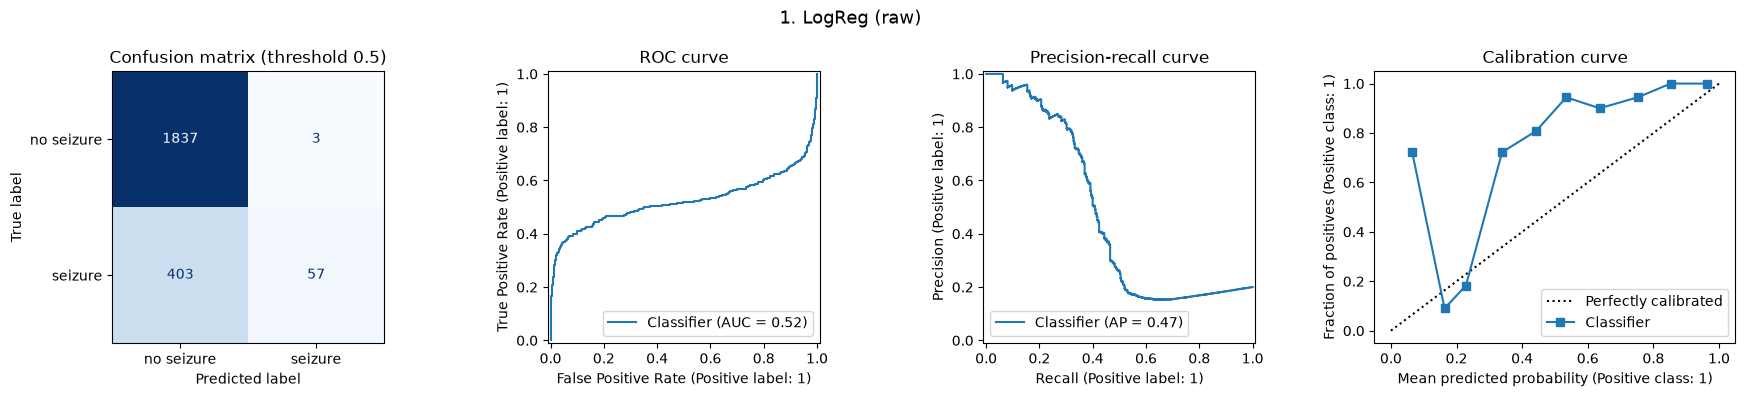

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.95,0.8201,0.5246,0.4699,0.1487


In [10]:
from sklearn.linear_model import LogisticRegression

model_1 = LogisticRegression(max_iter=1000, random_state=SEED)
train_and_evaluate("1. LogReg (raw)", model_1, X_train_s, X_val_s)

### Raw signals with a random forest
The 300 trees can learn nonlinear amplitude rules and interactions between samples.

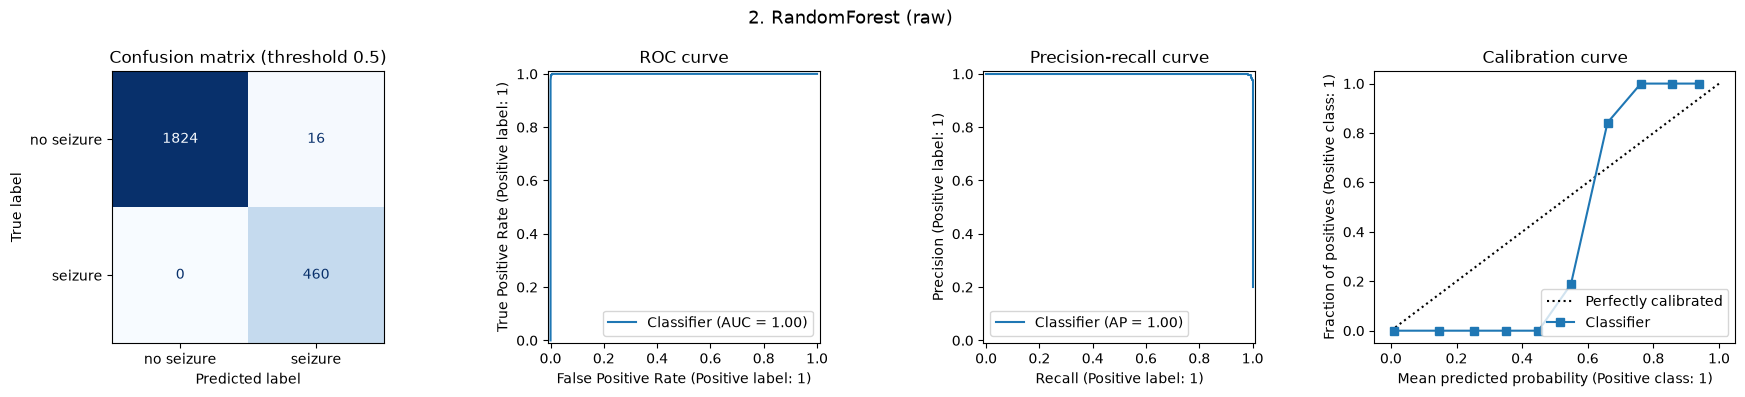

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5246,0.4699,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9999,0.0128


In [11]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=300, random_state=SEED)
train_and_evaluate("2. RandomForest (raw)", model_2, X_train, X_val)

### Raw signals with LightGBM
Gradient boosting fits successive trees to improve the current predictions.

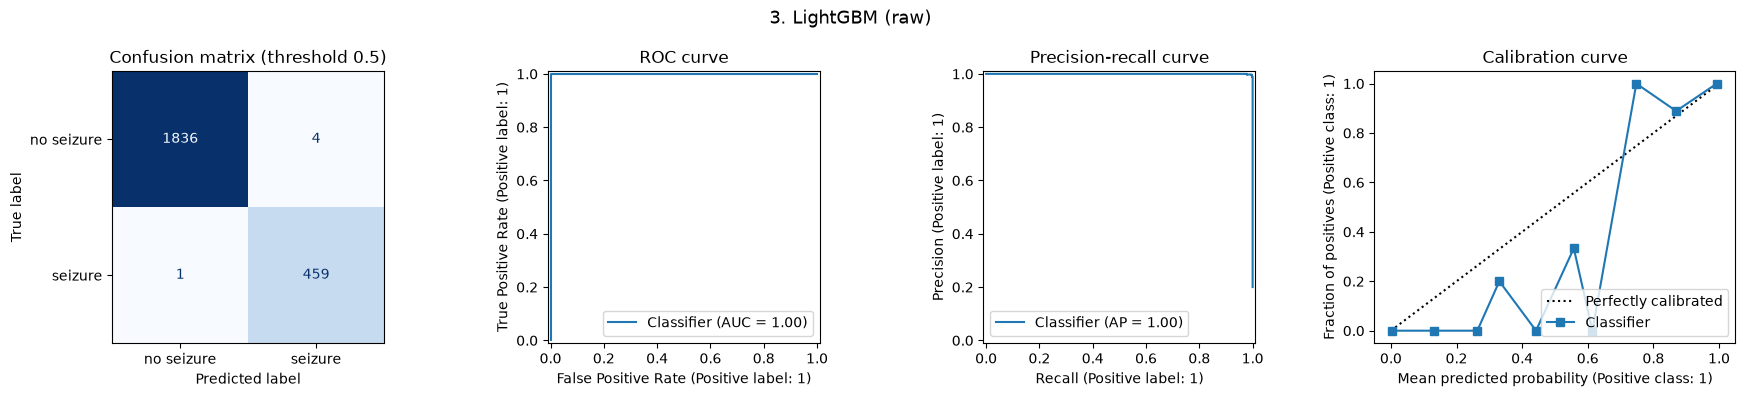

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5246,0.4699,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9999,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020


In [12]:
from lightgbm import LGBMClassifier

model_3 = LGBMClassifier(random_state=SEED, verbose=-1)
train_and_evaluate("3. LightGBM (raw)", model_3, X_train, X_val)

### Engineered features
The features summarise amplitude, movement between samples and spectral power. Welch's method uses the 173.61 Hz sampling rate reported in the [original Bonn study](https://www.upf.edu/documents/229517819/232450661/Andrzejak-PhysicalReviewE2001.pdf/0e9a54b8-8993-b400-743e-4d64fa29fb63). With about one second of signal, band estimates are coarse. The original 0.53-40 Hz acquisition passband limits interpretation of the upper gamma band.

In [13]:
from scipy.signal import welch

FS = 173.61
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 60)}

def make_features(X):
    f = pd.DataFrame()
    f["mean"] = X.mean(axis=1)
    f["std"] = X.std(axis=1)
    f["min"] = X.min(axis=1)
    f["max"] = X.max(axis=1)
    f["range"] = f["max"] - f["min"]
    f["energy"] = (X ** 2).sum(axis=1)
    centred = X - X.mean(axis=1, keepdims=True)
    f["zero_crossings"] = (np.diff(np.signbit(centred), axis=1) != 0).sum(axis=1)
    f["line_length"] = np.abs(np.diff(X, axis=1)).sum(axis=1)
    freqs, power = welch(X, fs=FS, nperseg=178, axis=1)
    for band, (low, high) in BANDS.items():
        f[band] = power[:, (freqs >= low) & (freqs < high)].sum(axis=1) * (freqs[1] - freqs[0])
    return f

F_train, F_val = make_features(X_train), make_features(X_val)
F_train.head()

,mean,std,min,max,range,energy,zero_crossings,line_length,delta,theta,alpha,beta,gamma
0,-16.910112,95.710958,-281,229,510,1681484,25,5700,2897.512978,142.314098,4620.500712,3739.842723,77.664067
1,-44.044944,44.186380,-126,80,206,692846,24,2458,390.831067,330.457326,278.041339,470.873259,8.614366
2,13.988764,64.883300,-137,141,278,784184,21,3753,163.205237,172.452113,1965.439123,359.350036,5.186916
3,-32.544944,37.104782,-118,39,157,433597,3,858,990.398972,264.184577,39.709295,22.707855,1.493708
4,-31.685393,151.798809,-400,419,819,4280338,12,5320,2407.349415,13134.075505,890.079602,1000.943721,44.151906


### Engineered features with logistic regression
Using the same model family helps isolate the effect of changing the input. The feature scaler is fitted on training rows.

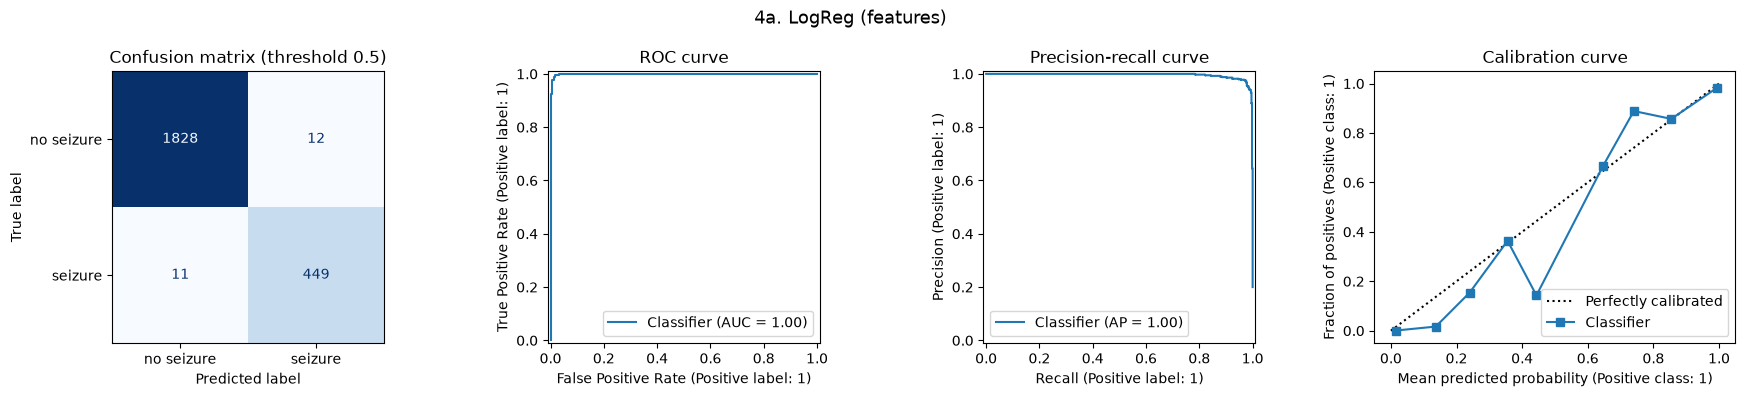

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5246,0.4699,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9999,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9959,0.0096


In [14]:
feat_scaler = StandardScaler().fit(F_train)
F_train_s = feat_scaler.transform(F_train)
F_val_s = feat_scaler.transform(F_val)

model_4a = LogisticRegression(max_iter=1000, random_state=SEED)
train_and_evaluate("4a. LogReg (features)", model_4a, F_train_s, F_val_s)

### Engineered features with LightGBM
The same boosting family provides a second comparison between raw and engineered inputs.

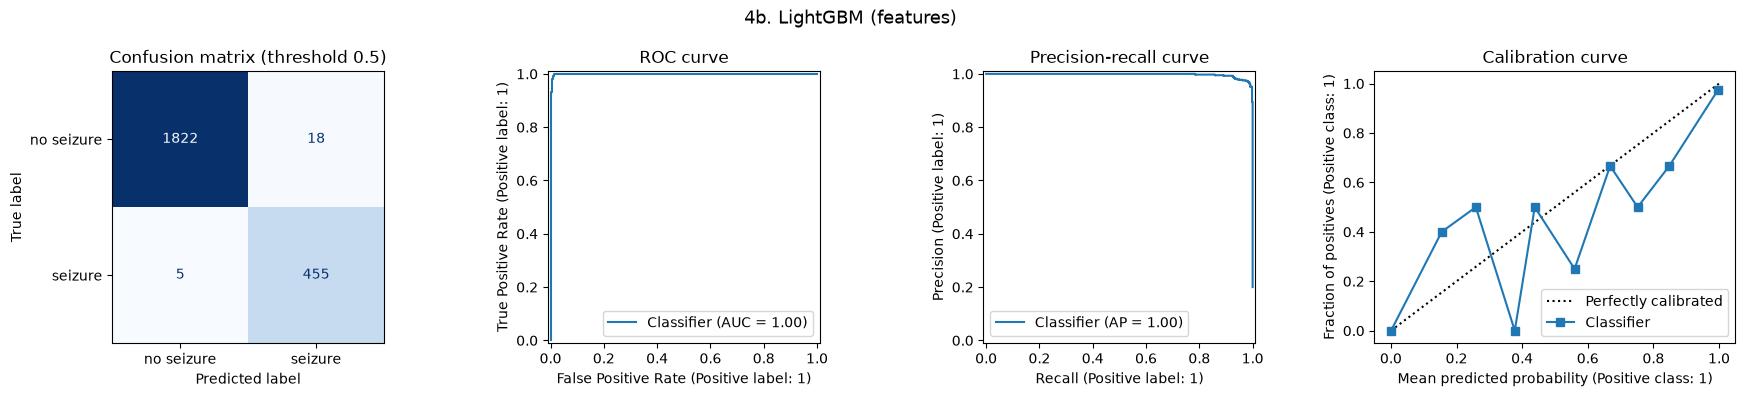

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5246,0.4699,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9999,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9959,0.0096
4b. LightGBM (features),455.0,18.0,1822.0,5.0,0.9900,0.9891,0.9902,0.9619,0.9973,0.9994,0.9974,0.0081


In [15]:
model_4b = LGBMClassifier(random_state=SEED, verbose=-1)
train_and_evaluate("4b. LightGBM (features)", model_4b, F_train, F_val)

### Step 5 — Change the approach: 1D CNN (deep learning)
The network learns its own patterns from the raw signal. It has 3 convolution layers, then a max-pool that finds the pattern anywhere in the segment.
The `fit` method contains the **training loop**: shuffle → mini-batch → predict → loss → backward → update weights.

In [16]:
try:
    import torch
    import torch.nn as nn
except (ImportError, OSError):
    torch = None
else:
    torch.set_num_threads(2)
    torch.use_deterministic_algorithms(True)

class CNN1D:
    def __init__(self, epochs=20, batch_size=64):
        torch.manual_seed(SEED)
        self.epochs, self.batch_size = epochs, batch_size
        # shapes are (channels, length) for one segment
        self.net = nn.Sequential(
            # Block 1: find small wave shapes
            nn.Conv1d(1, 16, kernel_size=7, padding=3),    # (1, 178)  -> (16, 178)  16 filters, each 7 values wide
            nn.ReLU(),                                     # (16, 178) -> (16, 178)  keep positive matches only
            nn.MaxPool1d(2),                               # (16, 178) -> (16, 89)   halve the length

            # Block 2: combine small shapes into bigger patterns
            nn.Conv1d(16, 32, kernel_size=5, padding=2),   # (16, 89)  -> (32, 89)
            nn.ReLU(),                                     # (32, 89)  -> (32, 89)
            nn.MaxPool1d(2),                               # (32, 89)  -> (32, 44)

            # Block 3: even more complex patterns
            nn.Conv1d(32, 64, kernel_size=3, padding=1),   # (32, 44)  -> (64, 44)
            nn.ReLU(),                                     # (64, 44)  -> (64, 44)
            nn.AdaptiveMaxPool1d(1),                       # (64, 44)  -> (64, 1)    strongest match anywhere in the segment

            # Classifier
            nn.Flatten(),                                  # (64, 1)   -> (64,)
            nn.Linear(64, 1),                              # (64,)     -> (1,)       one score: seizure or not
        )

    def to_tensor(self, X):
        return torch.tensor(X / self.scale, dtype=torch.float32).unsqueeze(1)   # shape (n, 1, 178)

    def fit(self, X, y):
        self.scale = X.std()                                   # from training data only
        Xt, yt = self.to_tensor(X), torch.tensor(y, dtype=torch.float32)
        optimizer = torch.optim.Adam(self.net.parameters(), lr=1e-3)
        loss_fn = nn.BCEWithLogitsLoss()

        for epoch in range(self.epochs):                       # training loop
            order = torch.randperm(len(Xt))                    # shuffle
            total_loss = 0
            for i in range(0, len(Xt), self.batch_size):       # mini-batches
                batch = order[i:i + self.batch_size]
                loss = loss_fn(self.net(Xt[batch]).squeeze(1), yt[batch])   # predict + error
                optimizer.zero_grad()
                loss.backward()                                # how to change each weight
                optimizer.step()                               # update weights
                total_loss += loss.item() * len(batch)
            print(f"epoch {epoch + 1:2d}   loss = {total_loss / len(Xt):.4f}")
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            p = torch.sigmoid(self.net(self.to_tensor(X))).squeeze(1).numpy()
        return np.column_stack([1 - p, p])                     # same format as sklearn

### Train the optional 1D CNN
The CNN learns local waveform features from raw samples. Validation metrics show how it compares with the classical models.

In [17]:
if torch is None:
    print("Optional CNN skipped because PyTorch could not be loaded.")
else:
    model_5 = CNN1D(epochs=20)
    display(train_and_evaluate("5. 1D CNN (raw)", model_5, X_train, X_val))

Optional CNN skipped because PyTorch could not be loaded.


In [18]:
val_table = pd.DataFrame(results).T
display(val_table.round(4))

raw_auc = val_table.loc[val_table.index.str.endswith("(raw)"), "ROC-AUC"]
feature_auc = val_table.loc[val_table.index.str.endswith("(features)"), "ROC-AUC"]
print(f"Best raw: {raw_auc.idxmax()} (ROC-AUC {raw_auc.max():.6f})")
print(f"Best engineered: {feature_auc.idxmax()} (ROC-AUC {feature_auc.max():.6f})")

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5246,0.4699,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9999,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9959,0.0096
4b. LightGBM (features),455.0,18.0,1822.0,5.0,0.9900,0.9891,0.9902,0.9619,0.9973,0.9994,0.9974,0.0081


Best raw: 3. LightGBM (raw) (ROC-AUC 0.999982)
Best engineered: 4b. LightGBM (features) (ROC-AUC 0.999357)


In the saved run, raw LightGBM achieved the highest validation ROC-AUC (0.999982), slightly ahead of LightGBM on engineered features (0.999357). For logistic regression, using engineered features increased ROC-AUC from 0.525 to 0.999. Amplitude summaries give a linear classifier access to waveform properties such as energy and peak-to-peak range. Raw tree models and the CNN can exploit information in the original samples. Engineered summaries compress away the order of most events, which can matter for short waveform patterns.

Peak-to-peak range is the difference between the highest and lowest samples. Standard deviation measures amplitude spread. Line length is the sum of the absolute changes between consecutive samples, which describes how much the trace moves over the segment.

## Part D. Validation and threshold selection
The validation plots above show each model's confusion matrix at threshold 0.5, along with its ROC, precision-recall and calibration curves. PR-AUC is the trapezoidal area under the precision-recall curve. The Brier score measures squared probability error. Lower values reflect smaller probability errors on this split.

For review prioritisation, a missed seizure segment can delay review and a false alarm adds to review workload. Set a validation sensitivity floor of 95%. For each model, take the highest observed threshold that meets the floor. Select the model with the fewest false positives at its threshold, breaking ties by higher sensitivity, then higher ROC-AUC and then by model name.

In [19]:
from sklearn.metrics import roc_curve

operating_points = {}
for name, prob in val_probs.items():
    _, sensitivity, thresholds = roc_curve(y_val, prob, drop_intermediate=False)
    threshold = thresholds[sensitivity >= 0.95].max()
    operating_points[name] = {"threshold": threshold, **get_metrics(y_val, prob, threshold)}

selection = pd.DataFrame.from_dict(operating_points, orient="index")
selection.index.name = "model"
selection = selection.reset_index().sort_values(
    ["FP", "sensitivity", "ROC-AUC", "model"],
    ascending=[True, False, False, True],
).set_index("model")
selected_name = selection.index[0]
selected_threshold = selection.iloc[0]["threshold"]
selected_metrics = selection.iloc[0]
display(selection.round(6))
print(f"Selected: {selected_name} at threshold {selected_threshold:.8g}")
print(f"False positives: {int(selected_metrics['FP'])}")
print(f"Expected true seizure segments per 100 validation flags: {100 * selected_metrics['PPV']:.1f}")
print(f"Baseline validation Brier score: {val_table.iloc[0]['Brier']:.4f}")
print(f"Selected model's validation Brier score: {selected_metrics['Brier']:.4f}")

,threshold,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
model,,,,,,,,,,,,,
3. LightGBM (raw),0.924369,437,0,1840,23,0.990000,0.95,1.000000,1.000000,0.987654,0.999982,0.999929,0.002049
2. RandomForest (raw),0.713333,437,0,1840,23,0.990000,0.95,1.000000,1.000000,0.987654,0.999963,0.999855,0.012780
4b. LightGBM (features),0.974181,437,9,1831,23,0.986087,0.95,0.995109,0.979821,0.987594,0.999357,0.997376,0.008080
4a. LogReg (features),0.805956,437,9,1831,23,0.986087,0.95,0.995109,0.979821,0.987594,0.998879,0.995857,0.009608
1. LogReg (raw),0.033787,437,1837,3,23,0.191304,0.95,0.001630,0.192172,0.115385,0.524575,0.469885,0.148718


Selected: 3. LightGBM (raw) at threshold 0.92436934
False positives: 0
Expected true seizure segments per 100 validation flags: 100.0
Baseline validation Brier score: 0.1487
Selected model's validation Brier score: 0.0020


Raw LightGBM and the random forest each reached 95% validation sensitivity with zero false positives at their respective thresholds. LightGBM won the ROC-AUC tiebreak. At its selected threshold of approximately 0.92436934, the validation PPV was 100%, corresponding to about 100 true seizure segments per 100 flags on this split. Its validation Brier score was 0.0020, compared with 0.1487 for the baseline.

PPV is the fraction of flagged segments that contain seizure activity. Multiplying it by 100 gives the estimate shown above for this validation population. Changes in seizure prevalence and case mix can change PPV. ROC-AUC measures ranking across thresholds. Curves can cross, so a model with a higher overall area can still produce more false alarms at the required sensitivity.

## Part E. Held-out test and error analysis
Freeze the model and threshold selected on validation. Make one set of test predictions and reuse it for metrics, recording-level bootstrap intervals and error analysis.

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
3. LightGBM (raw),356,0,1840,104,0.9548,0.7739,1.0,1.0,0.9465,0.9985,0.9948,0.0125


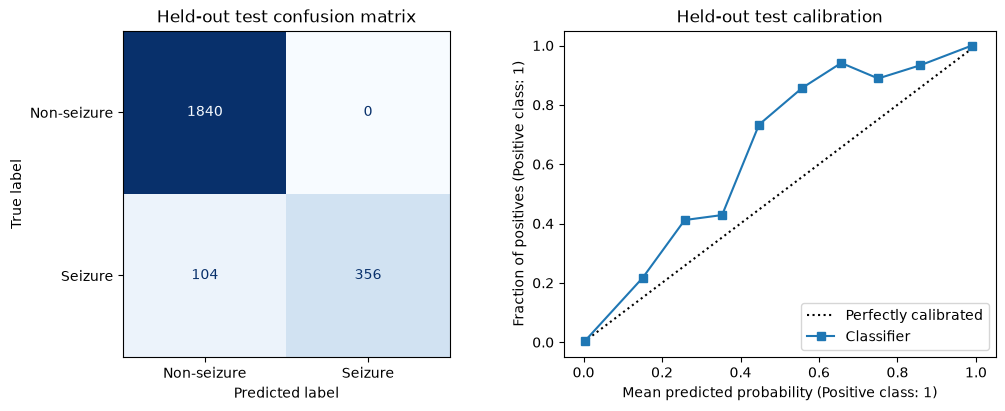

In [20]:
test = df.loc[held_out].copy()
X_test = test[SIGNAL_COLS].to_numpy()
y_test = test["seizure"].to_numpy()

model_inputs = {
    "1. LogReg (raw)": (model_1, lambda: scaler.transform(X_test)),
    "2. RandomForest (raw)": (model_2, lambda: X_test),
    "3. LightGBM (raw)": (model_3, lambda: X_test),
    "4a. LogReg (features)": (model_4a, lambda: feat_scaler.transform(make_features(X_test))),
    "4b. LightGBM (features)": (model_4b, lambda: make_features(X_test)),
}
if torch is not None:
    model_inputs["5. 1D CNN (raw)"] = (model_5, lambda: X_test)
selected_model, prepare_test = model_inputs[selected_name]
test_prob = selected_model.predict_proba(prepare_test())[:, 1]
test["predicted"] = (test_prob >= selected_threshold).astype(int)
test_metrics = get_metrics(y_test, test_prob, selected_threshold)
display(pd.DataFrame([test_metrics], index=[selected_name]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_test, test["predicted"], display_labels=["Non-seizure", "Seizure"],
    cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Held-out test confusion matrix")
CalibrationDisplay.from_predictions(y_test, test_prob, n_bins=10, ax=axes[1])
axes[1].set_title("Held-out test calibration")
plt.show()

In [21]:
test["false_positive"] = test["seizure"].eq(0) & test["predicted"].eq(1)
test["false_negative"] = test["seizure"].eq(1) & test["predicted"].eq(0)

recording_summary = test.groupby("recording_id").agg(
    label=("y", "first"),
    seizure=("seizure", "first"),
    segments=("seizure", "size"),
    flagged_segments=("predicted", "sum"),
    FP=("false_positive", "sum"),
    FN=("false_negative", "sum"),
)
rng = np.random.default_rng(SEED)
intervals = {}
for metric, label, error in [("sensitivity", 1, "FN"), ("specificity", 0, "FP")]:
    group = recording_summary.loc[recording_summary["seizure"].eq(label)]
    sizes = group["segments"].to_numpy()
    errors = group[error].to_numpy()
    draws = rng.integers(0, len(group), size=(5000, len(group)))
    rates = 1 - errors[draws].sum(axis=1) / sizes[draws].sum(axis=1)
    intervals[metric] = np.quantile(rates, [0.025, 0.975])

display(pd.DataFrame.from_dict(intervals, orient="index", columns=["2.5%", "97.5%"]).round(4))

,2.5%,97.5%
sensitivity,0.6391,0.9
specificity,1.0000,1.0


The 95% percentile intervals use 5,000 bootstrap draws within each binary class. Each draw includes all chunks of every sampled recording. The intervals describe variation across recordings in this split. A bound of 100% can arise from observing few or zero errors in a small sample. Patient-level uncertainty remains unknown because the data lack patient IDs.

,Original label,segments,FP,FN
y,,,,
1,Seizure,460,0,104
2,Tumour area,460,0,0
3,Healthy area in patient with tumour,460,0,0
4,"Healthy volunteer, eyes closed",460,0,0
5,"Healthy volunteer, eyes open",460,0,0


No non-seizure label produced a false positive at this threshold.


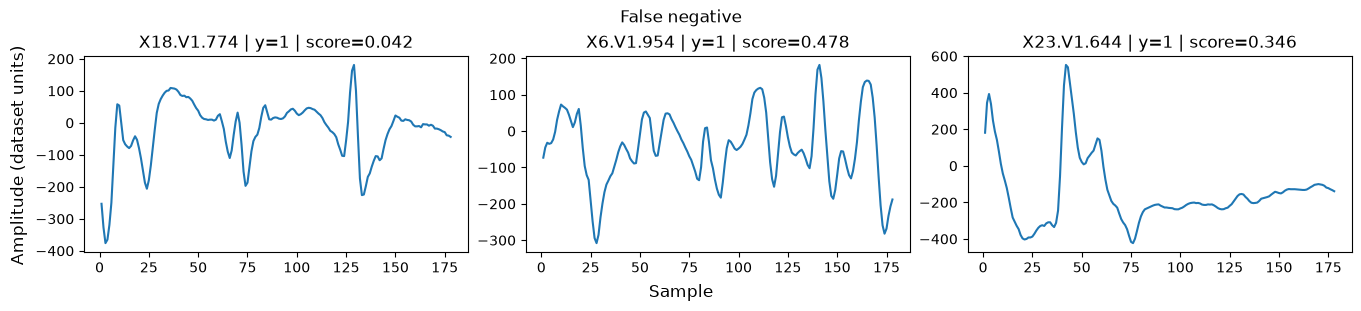

No false positive examples at the locked threshold.


In [22]:
errors_by_label = test.groupby("y").agg(
    segments=("y", "size"),
    FP=("false_positive", "sum"),
    FN=("false_negative", "sum"),
)
errors_by_label.insert(0, "Original label", pd.Series(LABEL_NAMES))
display(errors_by_label)

nonseizure_fp = errors_by_label.loc[2:5, "FP"]
if nonseizure_fp.max():
    leaders = nonseizure_fp.index[nonseizure_fp.eq(nonseizure_fp.max())]
    print("Highest false-positive count:", ", ".join(
        f"y={label} ({LABEL_NAMES[label]})" for label in leaders
    ), f"with {nonseizure_fp.max()} each.")
else:
    print("No non-seizure label produced a false positive at this threshold.")

for kind in ["false_negative", "false_positive"]:
    errors = test.loc[test[kind]].copy()
    if errors.empty:
        print(f"No {kind.replace('_', ' ')} examples at the locked threshold.")
        continue
    errors["score"] = test_prob[test[kind].to_numpy()]
    first_examples = errors.drop_duplicates("recording_id")
    extras = errors.loc[~errors.index.isin(first_examples.index)]
    examples = pd.concat([first_examples, extras]).head(3)
    fig, axes = plt.subplots(1, len(examples), figsize=(4.5 * len(examples), 3),
                             squeeze=False, layout="constrained")
    for ax, (_, row) in zip(axes[0], examples.iterrows()):
        ax.plot(range(1, 179), row[SIGNAL_COLS].to_numpy(dtype=float))
        ax.set_title(f"{row['id']} | y={row['y']} | score={row['score']:.3f}")
    fig.suptitle(kind.replace("_", " ").capitalize())
    fig.supxlabel("Sample")
    fig.supylabel("Amplitude (dataset units)")
    plt.show()

In [23]:
recording_summary["total_errors"] = recording_summary["FP"] + recording_summary["FN"]
affected = recording_summary.loc[recording_summary["total_errors"].gt(0)].sort_values(
    "total_errors", ascending=False
)
display(affected[["label", "segments", "FP", "FN", "total_errors"]])
print(f"{affected['total_errors'].sum()} erroneous chunks across {len(affected)} recordings.")
print(f"Recordings with multiple erroneous chunks: {affected['total_errors'].gt(1).sum()}.")

recording_positive = recording_summary["flagged_segments"].ge(1)
tn, fp, fn, tp = confusion_matrix(
    recording_summary["seizure"], recording_positive, labels=[0, 1]
).ravel()
unit_comparison = pd.DataFrame([
    {key: test_metrics[key] for key in ["TP", "FP", "TN", "FN", "sensitivity", "specificity"]},
    {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
     "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp)},
], index=["Segments", "Recordings (at least one flag)"])
display(unit_comparison.round(4))
change = unit_comparison[["sensitivity", "specificity"]].diff().iloc[-1] * 100
print(f"Recording-level change: sensitivity {change['sensitivity']:+.1f} percentage points, "
      f"specificity {change['specificity']:+.1f} percentage points.")

,label,segments,FP,FN,total_errors
recording_id,,,,,
V1.954,1,23,0,18,18
V1.634,1,23,0,18,18
V1.774,1,23,0,17,17
V1.624,1,23,0,14,14
V1.554,1,23,0,14,14
V1.616,1,23,0,9,9
V1.284,1,23,0,8,8
V1.644,1,23,0,5,5
V1.517,1,23,0,1,1


104 erroneous chunks across 9 recordings.
Recordings with multiple erroneous chunks: 8.


,TP,FP,TN,FN,sensitivity,specificity
Segments,356,0,1840,104,0.7739,1.0
Recordings (at least one flag),20,0,80,0,1.0000,1.0


Recording-level change: sensitivity +22.6 percentage points, specificity +0.0 percentage points.


At the locked threshold, all four non-seizure labels had zero false positives. This run therefore provides no evidence that a particular non-seizure label is more prone to false alarms. Large or abrupt fluctuations in non-seizure traces could trigger alerts in a different sample or at a lower threshold. The test waveforms shown above are false negatives.

The 104 missed segments came from nine recordings, and eight of those recordings had multiple misses. Two recordings each accounted for 18. This concentration suggests that chunks from the same recording can share signal characteristics that make the model assign lower scores. Test segment sensitivity fell from 95.0% on validation to 77.4%, despite a test ROC-AUC of 0.9985. The difference illustrates how strong ranking can coexist with a drop in sensitivity at a fixed threshold.

Flagging a recording when any segment was positive raised test sensitivity to 100% (20/20). Specificity stayed at 100% (80/80). Each seizure recording contained at least one detected chunk, and no non-seizure chunk triggered a flag in this split. In a larger sample, even one false positive can make a whole non-seizure recording count as a false alarm.

### Final results
Validation rows at 0.5 compare every model. The final two rows show the selected model at the locked threshold, first on validation and then on test.

In [24]:
validation_report = val_table.assign(split="Validation", threshold=0.5)
locked_validation_report = pd.DataFrame(
    [{**get_metrics(y_val, val_probs[selected_name], selected_threshold),
      "split": "Validation (selected)", "threshold": selected_threshold}],
    index=[selected_name],
)
test_report = pd.DataFrame(
    [{**test_metrics, "split": "Test", "threshold": selected_threshold}],
    index=[selected_name],
)
final_results = pd.concat([validation_report, locked_validation_report, test_report])
final_results.index.name = "Model"
final_results.set_index(["split", "threshold"], append=True).round(6)

TP    FP      TN  \
Model                   split                 threshold                        
1. LogReg (raw)         Validation            0.500000    57.0   3.0  1837.0   
2. RandomForest (raw)   Validation            0.500000   460.0  16.0  1824.0   
3. LightGBM (raw)       Validation            0.500000   459.0   4.0  1836.0   
4a. LogReg (features)   Validation            0.500000   449.0  12.0  1828.0   
4b. LightGBM (features) Validation            0.500000   455.0  18.0  1822.0   
3. LightGBM (raw)       Validation (selected) 0.924369   437.0   0.0  1840.0   
                        Test                  0.924369   356.0   0.0  1840.0   

                                                            FN  accuracy  \
Model                   split                 threshold                    
1. LogReg (raw)         Validation            0.500000   403.0  0.823478   
2. RandomForest (raw)   Validation            0.500000     0.0  0.993043   
3. LightGBM (raw)       Validation            0.500000     1.0  0.997826   
4a. LogReg (features)   Validation            0.500000    11.0  0.990000   
4b. LightGBM (features) Validation            0.500000     5.0  0.990000   
3. LightGBM (raw)       Validation (selected) 0.924369    23.0  0.990000   
                        Test                  0.924369   104.0  0.954783   

                                                         sensitivity  \
Model                   split                 threshold                
1. LogReg (raw)         Validation            0.500000      0.123913   
2. RandomForest (raw)   Validation            0.500000      1.000000   
3. LightGBM (raw)       Validation            0.500000      0.997826   
4a. LogReg (features)   Validation            0.500000      0.976087   
4b. LightGBM (features) Validation            0.500000      0.989130   
3. LightGBM (raw)       Validation (selected) 0.924369      0.950000   
                        Test                  0.924369      0.773913   

                                                         specificity  \
Model                   split                 threshold                
1. LogReg (raw)         Validation            0.500000      0.998370   
2. RandomForest (raw)   Validation            0.500000      0.991304   
3. LightGBM (raw)       Validation            0.500000      0.997826   
4a. LogReg (features)   Validation            0.500000      0.993478   
4b. LightGBM (features) Validation            0.500000      0.990217   
3. LightGBM (raw)       Validation (selected) 0.924369      1.000000   
                        Test                  0.924369      1.000000   

                                                              PPV       NPV  \
Model                   split                 threshold                       
1. LogReg (raw)         Validation            0.500000   0.950000  0.820089   
2. RandomForest (raw)   Validation            0.500000   0.966387  1.000000   
3. LightGBM (raw)       Validation            0.500000   0.991361  0.999456   
4a. LogReg (features)   Validation            0.500000   0.973970  0.994018   
4b. LightGBM (features) Validation            0.500000   0.961945  0.997263   
3. LightGBM (raw)       Validation (selected) 0.924369   1.000000  0.987654   
                        Test                  0.924369   1.000000  0.946502   

                                                          ROC-AUC    PR-AUC  \
Model                   split                 threshold                       
1. LogReg (raw)         Validation            0.500000   0.524575  0.469885   
2. RandomForest (raw)   Validation            0.500000   0.999963  0.999855   
3. LightGBM (raw)       Validation            0.500000   0.999982  0.999929   
4a. LogReg (features)   Validation            0.500000   0.998879  0.995857   
4b. LightGBM (features) Validation            0.500000   0.999357  0.997376   
3. LightGBM (raw)       Validation (selected) 0.924369   0.999982  0.999929   
            

## Part F. Reflection

The strong validation results show that the seizure labels are separable in this collection. The source contains selected single-channel excerpts from a small number of volunteers and patients. Some recordings use different electrode placements, so a model may partly learn acquisition or recording-site differences associated with the label. Grouping chunks by recording limits leakage, but the same person could contribute recordings to multiple splits. The five source labels were sampled equally, creating a 20% seizure rate that may differ substantially from routine monitoring. The short excerpts also omit information clinicians use, such as simultaneous channels, changes before and after the event, patient history and medication.

External validation should use continuous, multichannel EEG from independent patients across multiple hospitals and devices. Clinicians should annotate seizure events using a shared protocol and adjudicate ambiguous cases. A prospective silent evaluation should measure event sensitivity, detection delay, false alarms per monitoring hour, calibration and performance across patient groups before any workflow trial.

In a workflow trial, a clinician would inspect flagged excerpts with their surrounding EEG and make the final interpretation. Grouping adjacent flags into one review item could limit repeated interruptions. Alert fatigue should be measured through review time and alert volume, alongside missed events.